# U.S. National Park Service visitation analysis

This notebook analyses the official **NPS Visitor Use Statistics Data Package, 2025**
(IRMA reference 2317666, DOI `10.57830/2317666`, CC0), downloaded by
`scraper/scrape_nps_visitation.py` and normalised by `scraper/clean_visitation.py`.

- **Data period used: January 1979  to  December 2025**, monthly unit-level records.
- **Statistic analysed:** `TRV` (recreation visits). Counts are visits, not unique people.
- The Power BI dashboard on nps.gov is **not** scraped; the official CSV is the source.
- Input: `data/processed/nps_visitation_cleaned.csv` (override with `NPS_CLEANED_CSV`).
- Outputs: six PNGs in `reports/figures/`, tables in `reports/tables/`,
  `reports/findings.md`, and `reports/analysis_summary.json`.

Rebuild with:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/visitation_analysis.ipynb
```

In [1]:
%matplotlib inline

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd()
if not (ROOT / "scraper").exists():
    ROOT = ROOT.parent

def project_path(value, default):
    path = Path(value) if value else default
    path = path.expanduser()
    return path if path.is_absolute() else (ROOT / path).resolve()


DATA_PATH = project_path(os.environ.get("NPS_CLEANED_CSV"), ROOT / "data/processed/nps_visitation_cleaned.csv")
REPORT_DIR = project_path(os.environ.get("NPS_REPORT_DIR"), ROOT / "reports")
FIG_DIR = project_path(os.environ.get("NPS_FIG_DIR"), REPORT_DIR / "figures")
TABLE_DIR = REPORT_DIR / "tables"
for directory in (FIG_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

ACCESS_DATE = "2026-10-07"
SOURCE_NOTE = (
    "Source: NPS Visitor Use Statistics Data Package, 2025 (IRMA 2317666; "
    "DOI 10.57830/2317666), Main_Data.csv, statistic TRV. "
    f"Accessed {ACCESS_DATE}. The Power BI dashboard was not scraped."
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linewidth": 0.7,
        "figure.facecolor": "white",
    }
)
MILLIONS = FuncFormatter(lambda value, _pos: f"{value / 1e6:,.0f}")


def add_source(fig, extra=""):
    text = (extra + " " if extra else "") + SOURCE_NOTE
    fig.text(0.005, -0.06, text, fontsize=8, color="#555555", ha="left", va="top")


def save(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    return path


if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned CSV not found: {DATA_PATH}. Run the scraper and cleaner first, "
        "or set NPS_CLEANED_CSV. Refusing to substitute synthetic fixture data."
    )
print(f"Input: {DATA_PATH}")

Input: /home/runner/work/national-park-visitation-toolkit/national-park-visitation-toolkit/data/processed/nps_visitation_cleaned.csv


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
required = ["unit_code", "year", "month", "date", "statistic", "statistic_label", "value"]
missing_columns = [column for column in required if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
df["month"] = pd.to_numeric(df["month"], errors="coerce").astype("Int64")
df["value"] = pd.to_numeric(df["value"], errors="coerce")

checks = pd.DataFrame(
    [
        ("rows", f"{len(df):,}"),
        ("unit codes", f"{df['unit_code'].nunique():,}"),
        ("statistic codes", ", ".join(sorted(df["statistic"].unique()))),
        ("months covered", f"{df['date'].min():%Y-%m} to {df['date'].max():%Y-%m}"),
        ("rows with unparsable date", f"{int(df['date'].isna().sum()):,}"),
        ("rows with non-numeric value", f"{int(df['value'].isna().sum()):,}"),
        ("duplicate unit-year-month-statistic rows", f"{int(df.duplicated(['unit_code', 'year', 'month', 'statistic']).sum()):,}"),
    ],
    columns=["check", "result"],
)
display(checks)

trv = df[df["statistic"] == "TRV"].dropna(subset=["year", "value"]).copy()
LATEST_YEAR = int(trv["year"].max())
BASE_YEAR = 2019
print(f"TRV rows: {len(trv):,}; latest finalized year in the data: {LATEST_YEAR}; baseline year: {BASE_YEAR}")

,check,result
0,rows,"2,905,377"
1,unit codes,406
2,statistic codes,"BC, CCG, CL, MISC, NROS, TH, TNRV, TNRVH, TOS,..."
3,months covered,1979-01 to 2025-12
4,rows with unparsable date,0
5,rows with non-numeric value,0
6,duplicate unit-year-month-statistic rows,0


TRV rows: 193,692; latest finalized year in the data: 2025; baseline year: 2019


## 1. Annual system-wide recreation visits, 1979 to 2025

Annual totals are the sum of the twelve monthly `TRV` records in the cleaned CSV.
The set of reporting units grows over time, so part of the long-run change reflects
coverage rather than attendance.

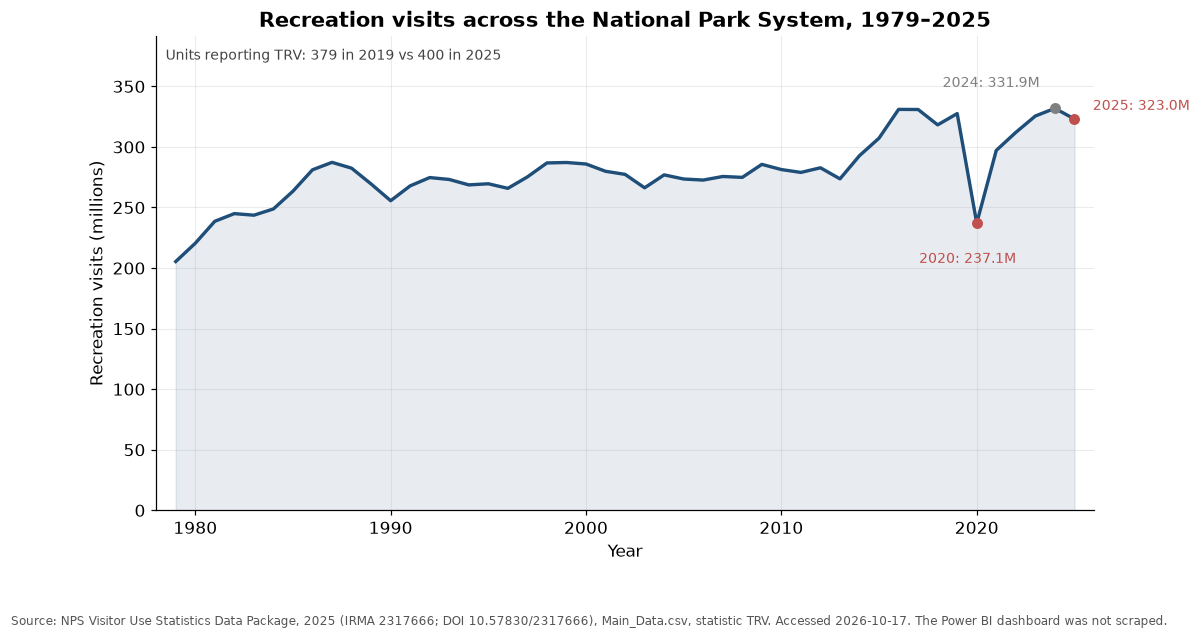

**Finding 1.** Recreation visits totalled **205.4 million in 1979** and **323.0 million in 2025**. The highest value in the series is **331.9 million in 2024**; 2025 is -2.7% below that peak. Coverage differs across the series (271 units in 1979 vs 400 in 2025), so the long-run shape is not a pure attendance trend.

In [3]:
annual = trv.groupby("year")["value"].sum()
units_per_year = trv.groupby("year")["unit_code"].nunique()
years = annual.index.astype(int)

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.plot(years, annual.values, color="#1f4e79", linewidth=2.2)
ax.fill_between(years, annual.values, color="#1f4e79", alpha=0.10)
callouts = {
    2020: ("#c0504d", (-6, -26), "center"),
    2024: ("#7f7f7f", (-10, 14), "right"),
    2025: ("#c0504d", (12, 6), "left"),
}
for year, (colour, offset, align) in callouts.items():
    if year in annual.index:
        ax.scatter([year], [annual.loc[year]], color=colour, zorder=5, s=38)
        ax.annotate(
            f"{year}: {annual.loc[year] / 1e6:,.1f}M",
            (year, annual.loc[year]),
            textcoords="offset points",
            xytext=offset,
            ha=align,
            fontsize=9,
            color=colour,
        )
ax.set_title("Recreation visits across the National Park System, 1979 to 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Recreation visits (millions)")
ax.yaxis.set_major_formatter(MILLIONS)
ax.set_xlim(years.min() - 1, years.max() + 1)
ax.set_ylim(0, annual.max() * 1.18)
ax.annotate(
    f"Units reporting TRV: {units_per_year.loc[2019]:,} in 2019 vs {units_per_year.loc[LATEST_YEAR]:,} in {LATEST_YEAR}",
    xy=(0.01, 0.95),
    xycoords="axes fraction",
    fontsize=9,
    color="#444444",
)
add_source(fig)
save(fig, "01_annual_recreation_visits.png")
plt.show()

first, last = annual.iloc[0], annual.iloc[-1]
peak_year = int(annual.idxmax())
display(Markdown(
    f"**Finding 1.** Recreation visits totalled **{first / 1e6:,.1f} million in {years.min()}** "
    f"and **{last / 1e6:,.1f} million in {LATEST_YEAR}**. The highest value in the series is "
    f"**{annual.max() / 1e6:,.1f} million in {peak_year}**; {LATEST_YEAR} is "
    f"{(last / annual.max() - 1) * 100:,.1f}% below that peak. "
    f"Coverage differs across the series ({units_per_year.loc[years.min()]} units in {years.min()} "
    f"vs {units_per_year.loc[LATEST_YEAR]} in {LATEST_YEAR}), so the long-run shape is not a pure attendance trend."
))

## 2. The ten most-visited units in 2025

Unit labels are the official four-letter NPS `UnitCode`s. The data package contains
**no display names**: it identifies units only by code. The short names shown here are
editorial labels for readability, not fields in the download, and the chart is driven
entirely by the codes and the counts.

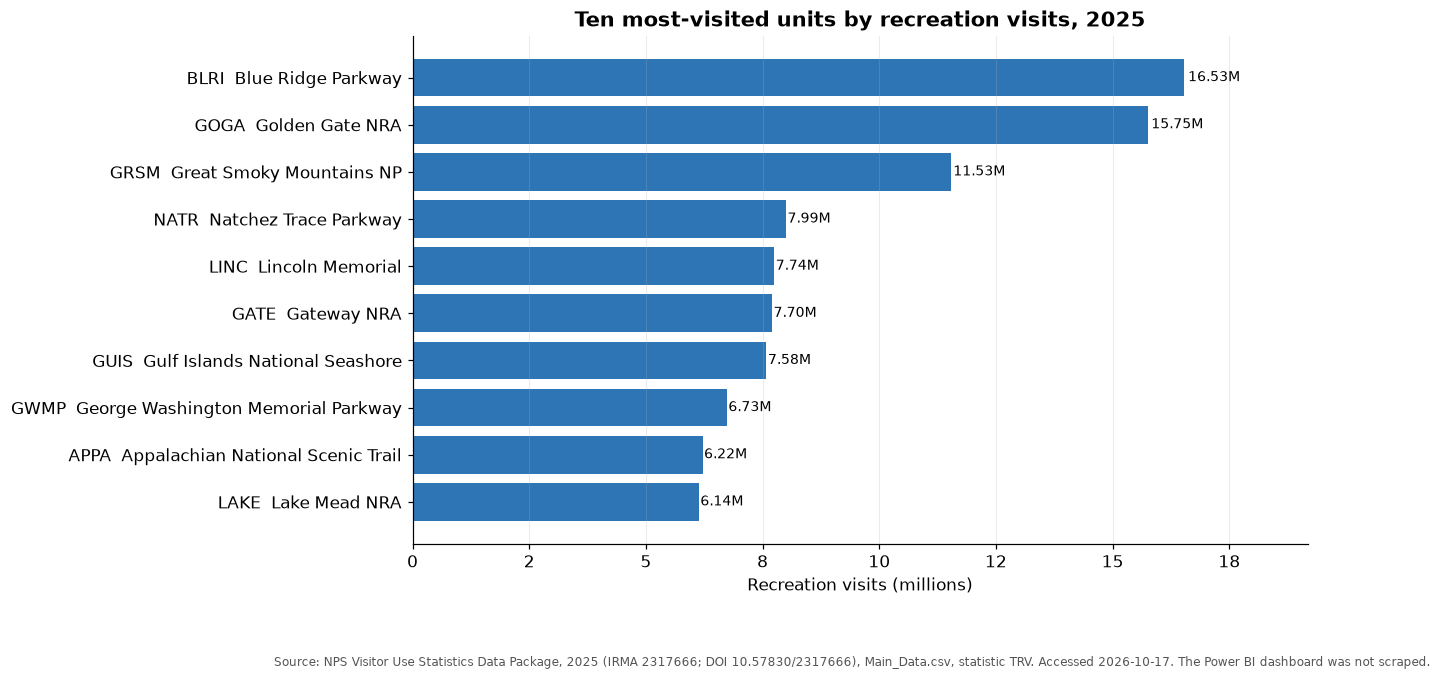

**Finding 2.** The ten most-visited units recorded **93.9 million recreation visits** in 2025, **29.1%** of the **323.0 million** system total. **BLRI** (Blue Ridge Parkway) led with **16.5 million** (5.1% of the total).

In [4]:
UNIT_NAMES = {
    "BLRI": "Blue Ridge Parkway",
    "GOGA": "Golden Gate NRA",
    "GRSM": "Great Smoky Mountains NP",
    "NATR": "Natchez Trace Parkway",
    "LINC": "Lincoln Memorial",
    "GATE": "Gateway NRA",
    "GUIS": "Gulf Islands National Seashore",
    "GWMP": "George Washington Memorial Parkway",
    "APPA": "Appalachian National Scenic Trail",
    "LAKE": "Lake Mead NRA",
    "ZION": "Zion NP",
    "VIVE": "Vicksburg NMP",
    "YELL": "Yellowstone NP",
    "CHOH": "Chesapeake & Ohio Canal NHP",
    "GRCA": "Grand Canyon NP",
}

latest_totals = (
    trv[trv["year"] == LATEST_YEAR]
    .groupby("unit_code")["value"]
    .sum()
    .sort_values(ascending=False)
)
top10 = latest_totals.head(10)
system_total_latest = latest_totals.sum()

fig, ax = plt.subplots(figsize=(10.5, 6))
labels = [
    f"{code}  {UNIT_NAMES[code]}" if UNIT_NAMES.get(code) else code
    for code in top10.index[::-1]
]
bars = ax.barh(labels, top10.values[::-1], color="#2e75b6")
for bar, value in zip(bars, top10.values[::-1]):
    ax.text(value * 1.005, bar.get_y() + bar.get_height() / 2, f"{value / 1e6:,.2f}M",
            va="center", fontsize=9)
ax.set_title(f"Ten most-visited units by recreation visits, {LATEST_YEAR}")
ax.set_xlabel("Recreation visits (millions)")
ax.xaxis.set_major_formatter(MILLIONS)
ax.set_xlim(0, top10.max() * 1.16)
ax.grid(axis="y", visible=False)
add_source(fig)
save(fig, "02_top10_units_2025.png")
plt.show()

share = top10.sum() / system_total_latest * 100
display(Markdown(
    f"**Finding 2.** The ten most-visited units recorded **{top10.sum() / 1e6:,.1f} million recreation visits** "
    f"in {LATEST_YEAR}, **{share:,.1f}%** of the **{system_total_latest / 1e6:,.1f} million** system total. "
    f"**{top10.index[0]}** ({UNIT_NAMES.get(top10.index[0], top10.index[0])}) led with "
    f"**{top10.iloc[0] / 1e6:,.1f} million** ({top10.iloc[0] / system_total_latest * 100:,.1f}% of the total)."
))

## 3. Monthly seasonal pattern

Seasonality is summarised as the mean monthly recreation-visit total across 2015 to 2025,
so that one unusual year does not define the shape. The 2020 pandemic year is included
and is visible as a lower year, but the eleven-year mean is dominated by the other years.

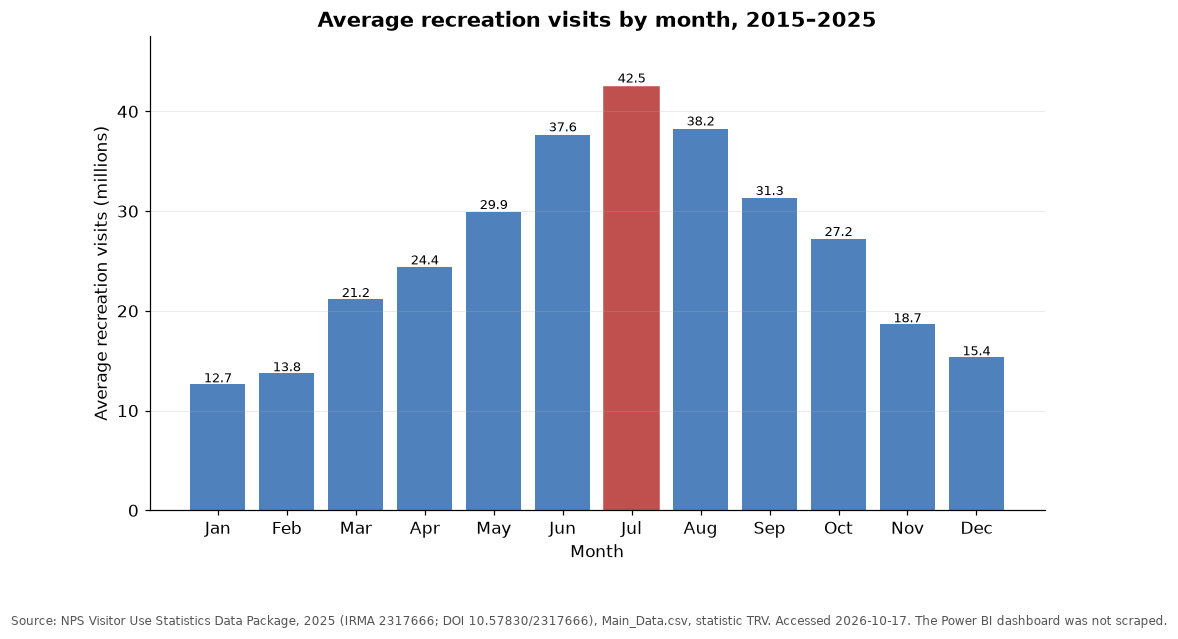

**Finding 3.** Visits are strongly seasonal: **Jul** averages **42.5 million** visits, versus **12.7 million** in **Jan**. The peak month carries **13.6%** of an average year's visits.

In [5]:
recent = trv[(trv["year"] >= 2015) & (trv["year"] <= 2025)]
monthly_year = recent.groupby(["year", "month"])["value"].sum().reset_index()
seasonal = monthly_year.groupby("month")["value"].mean()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10.5, 5.6))
bars = ax.bar(month_labels, seasonal.values, color="#4f81bd")
peak_month = int(seasonal.idxmax())
bars[peak_month - 1].set_color("#c0504d")
for bar, value in zip(bars, seasonal.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.01, f"{value / 1e6:,.1f}",
            ha="center", fontsize=8.5)
ax.set_title("Average recreation visits by month, 2015 to 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Average recreation visits (millions)")
ax.yaxis.set_major_formatter(MILLIONS)
ax.set_ylim(0, seasonal.max() * 1.12)
ax.grid(axis="x", visible=False)
add_source(fig)
save(fig, "03_monthly_seasonality.png")
plt.show()

annual_mean = recent.groupby("year")["value"].sum().mean()
display(Markdown(
    f"**Finding 3.** Visits are strongly seasonal: **{month_labels[peak_month - 1]}** averages "
    f"**{seasonal.max() / 1e6:,.1f} million** visits, versus **{seasonal.min() / 1e6:,.1f} million** in "
    f"**{month_labels[int(seasonal.idxmin()) - 1]}**. The peak month carries "
    f"**{seasonal.max() / annual_mean * 100:,.1f}%** of an average year's visits."
))

## 4. 2019, 2020 and 2025 compared

2019 is the last full pre-pandemic year, 2020 the pandemic year, and 2025 the latest
finalized year in the package. Percent changes compare totals, not matched units; see
chart 5 for a park-level comparison.

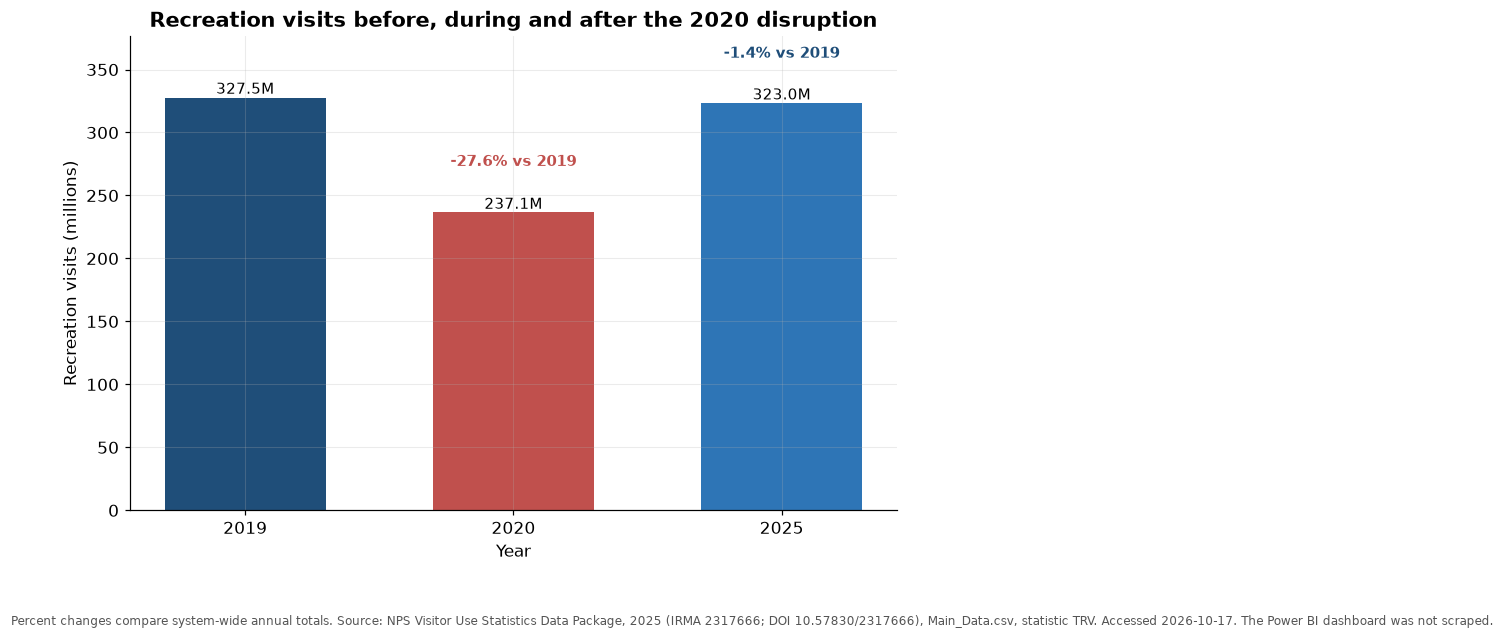

**Finding 4.** System-wide recreation visits fell from **327.5 million in 2019** to **237.1 million in 2020** (**-27.6%**), then recovered to **323.0 million in 2025** (**-1.4%** vs 2019). These are descriptive comparisons; the data alone do not identify causes.

In [6]:
compare_years = [BASE_YEAR, 2020, LATEST_YEAR]
compare = annual.reindex(compare_years)

fig, ax = plt.subplots(figsize=(9, 5.6))
colours = ["#1f4e79", "#c0504d", "#2e75b6"]
bars = ax.bar([str(year) for year in compare_years], compare.values, color=colours, width=0.6)
for bar, year in zip(bars, compare_years):
    value = compare.loc[year]
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.01, f"{value / 1e6:,.1f}M",
            ha="center", fontsize=10)

pct_2020 = (compare.loc[2020] / compare.loc[2019] - 1) * 100
pct_2025 = (compare.loc[LATEST_YEAR] / compare.loc[2019] - 1) * 100
ax.set_title("Recreation visits before, during and after the 2020 disruption")
ax.set_xlabel("Year")
ax.set_ylabel("Recreation visits (millions)")
ax.yaxis.set_major_formatter(MILLIONS)
ax.set_ylim(0, compare.max() * 1.15)
ax.annotate(f"{pct_2020:+.1f}% vs 2019", xy=(1, compare.loc[2020]), xytext=(0, 30),
            textcoords="offset points", ha="center", fontsize=10, color="#c0504d", fontweight="bold")
ax.annotate(f"{pct_2025:+.1f}% vs 2019", xy=(2, compare.loc[LATEST_YEAR]), xytext=(0, 30),
            textcoords="offset points", ha="center", fontsize=10, color="#1f4e79", fontweight="bold")
add_source(fig, "Percent changes compare system-wide annual totals.")
save(fig, "04_2019_2020_2025_comparison.png")
plt.show()

display(Markdown(
    f"**Finding 4.** System-wide recreation visits fell from **{compare.loc[2019] / 1e6:,.1f} million in 2019** "
    f"to **{compare.loc[2020] / 1e6:,.1f} million in 2020** (**{pct_2020:,.1f}%**), then recovered to "
    f"**{compare.loc[LATEST_YEAR] / 1e6:,.1f} million in {LATEST_YEAR}** (**{pct_2025:+,.1f}%** vs 2019). "
    "These are descriptive comparisons; the data alone do not identify causes."
))

## 5. Park-level change, 2019 → 2025

**Comparability rules.** A unit is included only if it reports `TRV` in **both** 2019 and
2025. Percent change is `(2025 − 2019) / 2019 × 100`.

- Units with a **missing** value in either year are excluded.
- Units with a **zero** 2019 baseline are excluded from percent change because division by
  zero is undefined; they are counted in the subtitle rather than shown as infinite growth.
- Units that first appear after 2019 are therefore not treated as "new parks" with a change.

The histogram is clipped to -100% … +250%; parks outside that range are counted in the subtitle.

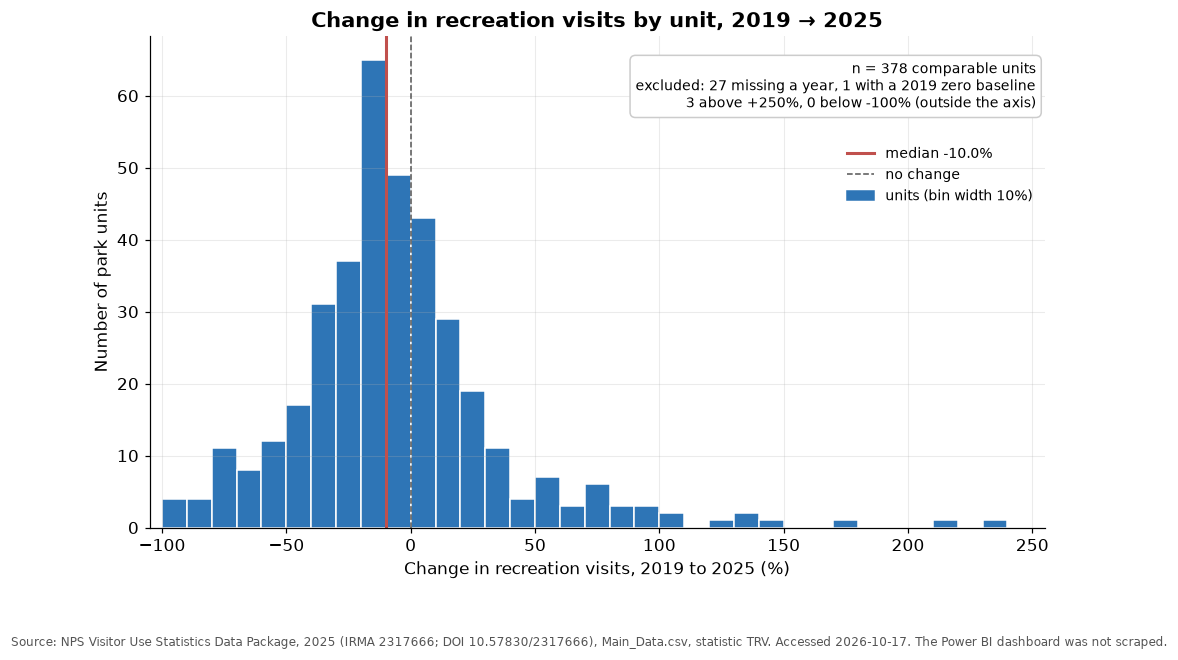

**Finding 5.** Of **378** units comparable between 2019 and 2025, **140** recorded more recreation visits and **238** fewer. The median change was **-10.0%** (interquartile range -27.8% to +10.3%). **27** units lacked a 2019 or 2025 value and **1** had a zero 2019 baseline, so their percent change is undefined and they are not ranked.

In [7]:
pivot = trv.pivot_table(index="unit_code", columns="year", values="value", aggfunc="sum")
has_both = pivot[[BASE_YEAR, LATEST_YEAR]].notna().all(axis=1)
zero_base = has_both & (pivot[BASE_YEAR] == 0)
comparable = has_both & (pivot[BASE_YEAR] > 0)

change = pd.DataFrame(
    {
        "visits_2019": pivot.loc[has_both, BASE_YEAR],
        "visits_2025": pivot.loc[has_both, LATEST_YEAR],
    }
)
change["pct_change"] = (change["visits_2025"] / change["visits_2019"] - 1) * 100
change["comparable"] = comparable.reindex(change.index).fillna(False).astype(bool)
change["zero_baseline"] = zero_base.reindex(change.index).fillna(False).astype(bool)

pct = change.loc[change["comparable"], "pct_change"].dropna()
missing_both = int((~has_both).sum())
zero_count = int(zero_base.sum())
beyond = int((pct > 250).sum())
below_floor = int((pct < -100).sum())
plot_pct = pct[(pct <= 250) & (pct >= -100)]

fig, ax = plt.subplots(figsize=(10.5, 5.8))
bins = np.arange(-100, 251, 10)
ax.hist(plot_pct, bins=bins, color="#2e75b6", edgecolor="white")
median_line = ax.axvline(pct.median(), color="#c0504d", linewidth=2)
zero_line = ax.axvline(0, color="#555555", linewidth=1, linestyle="--")
ax.legend(
    [median_line, zero_line, plt.Rectangle((0, 0), 1, 1, color="#2e75b6")],
    [f"median {pct.median():+.1f}%", "no change", "units (bin width 10%)"],
    loc="upper right", bbox_to_anchor=(1.0, 0.80), frameon=False, fontsize=9,
)
ax.set_title(f"Change in recreation visits by unit, {BASE_YEAR} → {LATEST_YEAR}")
ax.set_xlabel(f"Change in recreation visits, {BASE_YEAR} to {LATEST_YEAR} (%)")
ax.set_ylabel("Number of park units")
ax.set_xlim(-105, 255)
ax.text(
    0.99, 0.95,
    f"n = {len(pct):,} comparable units\n"
    f"excluded: {missing_both:,} missing a year, {zero_count:,} with a 2019 zero baseline\n"
    f"{beyond:,} above +250%, {below_floor:,} below -100% (outside the axis)",
    transform=ax.transAxes, ha="right", va="top", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc"),
)
add_source(fig)
save(fig, "05_park_change_2019_2025.png")
plt.show()

below = int((pct < 0).sum())
above = int((pct > 0).sum())
display(Markdown(
    f"**Finding 5.** Of **{len(pct):,}** units comparable between {BASE_YEAR} and {LATEST_YEAR}, "
    f"**{above:,}** recorded more recreation visits and **{below:,}** fewer. The median change was "
    f"**{pct.median():+.1f}%** (interquartile range {pct.quantile(0.25):+.1f}% to {pct.quantile(0.75):+.1f}%). "
    f"**{missing_both:,}** units lacked a {BASE_YEAR} or {LATEST_YEAR} value and **{zero_count:,}** had a zero "
    f"{BASE_YEAR} baseline, so their percent change is undefined and they are not ranked."
))

## 6. Share of visits at the ten most-visited units

For each year the ten largest units by `TRV` are selected for **that year** (the membership
changes as units begin or stop reporting), then their combined visits are divided by the
system total for the same year. This is a concentration measure, not a fixed group of parks.

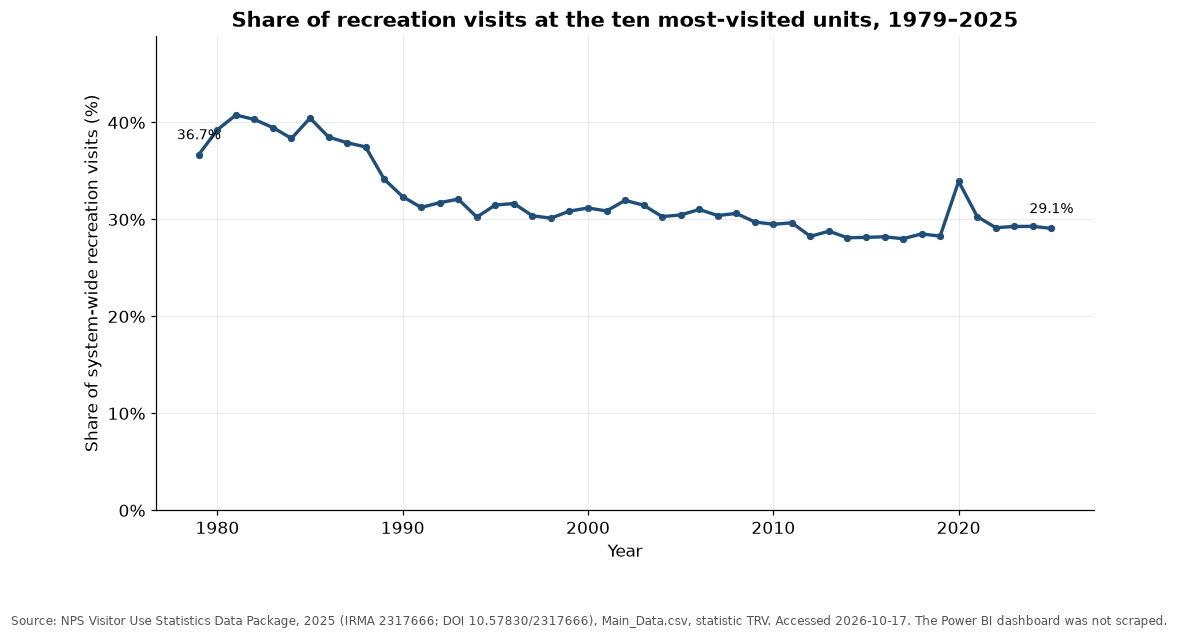

**Finding 6.** The ten most-visited units accounted for **36.7%** of system-wide recreation visits in **1979** and **29.1%** in **2025**. The share ranged from **28.0%** to **40.8%** across the series. Because the top-ten set is recomputed annually, this measures concentration, not the same ten parks.

In [8]:
rows = []
for year, group in trv.groupby("year"):
    totals = group.groupby("unit_code")["value"].sum()
    if len(totals) < 10:
        continue
    rows.append(
        {
            "year": int(year),
            "top10_visits": float(totals.nlargest(10).sum()),
            "total_visits": float(totals.sum()),
            "units_reporting": int(len(totals)),
        }
    )
concentration = pd.DataFrame(rows).sort_values("year").reset_index(drop=True)
concentration["share_pct"] = concentration["top10_visits"] / concentration["total_visits"] * 100

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.plot(concentration["year"], concentration["share_pct"], color="#1f4e79", linewidth=2.2)
ax.scatter(concentration["year"], concentration["share_pct"], s=14, color="#1f4e79")
for year in (concentration["year"].min(), LATEST_YEAR):
    row = concentration[concentration["year"] == year].iloc[0]
    ax.annotate(f"{row['share_pct']:,.1f}%", xy=(year, row["share_pct"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Share of recreation visits at the ten most-visited units, 1979 to 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Share of system-wide recreation visits (%)")
ax.set_ylim(0, concentration["share_pct"].max() * 1.2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{value:.0f}%"))
add_source(fig)
save(fig, "06_top10_share_over_time.png")
plt.show()

first_share = concentration.iloc[0]
last_share = concentration.iloc[-1]
display(Markdown(
    f"**Finding 6.** The ten most-visited units accounted for **{first_share['share_pct']:,.1f}%** of "
    f"system-wide recreation visits in **{int(first_share['year'])}** and **{last_share['share_pct']:,.1f}%** "
    f"in **{LATEST_YEAR}**. The share ranged from "
    f"**{concentration['share_pct'].min():,.1f}%** to **{concentration['share_pct'].max():,.1f}%** across the series. "
    f"Because the top-ten set is recomputed annually, this measures concentration, not the same ten parks."
))

## Limitations

- **Counting procedures change over time.** NPS reporting guidance, counting methods and
  the roster of reporting units have changed since 1979, so long-run comparisons mix real
  change with methodological change. Some values are estimates from automated counters or
  staff sampling.
- **Coverage is incomplete and uneven.** The package has 406 unit codes, while the NPS page
  reports 406 of 433 units reporting for 2025. Units enter and leave the series; the number
  of reporting units differs by year (shown in chart 1).
- **Missing is not zero.** The cleaned file drops blank values instead of filling them with
  zero. A missing monthly record therefore reduces that unit's annual total rather than
  contributing zero.
- **Zero baselines and missing years.** Percent change is undefined for units with no 2019
  record or a 2019 value of zero; such units are excluded from chart 5 rather than ranked.
- **Data-quality edits are explicit.** The cleaner flagged 63 negative source values in the
  official CSV (mostly `TNRV`/`TNRVH` in a handful of unit-years) and `Main_Data.csv` has
  no duplicate keys. Flagged rows are dropped and listed in
  `data/processed/nps_data_quality_issues.csv`.
- **Visits are not people.** `TRV` counts recreation visit entries, not unique visitors, and
  the definition of a "visit" varies by unit type (for example parkways and trails).
- **No causal claims.** The charts describe patterns. They do not identify why visitation
  changed (weather, closures, fees, gas prices, population, and reporting changes are not
  measured here).
- **Period used.** Analysis is restricted to the downloaded package's finalised coverage,
  **January 1979  to  December 2025**; 2026 data is preliminary and excluded.

## Outputs

Tables and a machine-readable summary are written alongside this notebook's figures.

In [9]:
change_out = change.reset_index().rename(columns={"index": "unit_code"})
change_out = change_out[["unit_code", "visits_2019", "visits_2025", "pct_change", "comparable", "zero_baseline"]]
change_out.to_csv(TABLE_DIR / "park_change_2019_2025.csv", index=False)

annual_table = pd.DataFrame({
    "year": annual.index.astype(int),
    "recreation_visits": annual.values,
    "units_reporting": units_per_year.reindex(annual.index).astype(int).values,
})
annual_table.to_csv(TABLE_DIR / "annual_recreation_visits.csv", index=False)

top10_table = pd.DataFrame({
    "rank": range(1, 11),
    "unit_code": top10.index,
    "unit_name": [UNIT_NAMES.get(code, code) for code in top10.index],
    "recreation_visits": top10.values,
    "share_of_system_pct": top10.values / system_total_latest * 100,
})
top10_table.to_csv(TABLE_DIR / "top10_units_2025.csv", index=False)

seasonal_table = pd.DataFrame({
    "month": seasonal.index.astype(int),
    "month_name": month_labels,
    "average_recreation_visits_2015_2025": seasonal.values,
})
seasonal_table.to_csv(TABLE_DIR / "monthly_seasonality_2015_2025.csv", index=False)
concentration.to_csv(TABLE_DIR / "top10_share_by_year.csv", index=False)

annual_unit = trv.groupby(["year", "unit_code"], as_index=False)["value"].sum()
annual_unit = annual_unit.rename(columns={"value": "recreation_visits"})
annual_unit.to_csv(TABLE_DIR / "annual_unit_recreation_visits.csv", index=False)

try:
    data_file_label = str(DATA_PATH.relative_to(ROOT))
except ValueError:
    data_file_label = str(DATA_PATH)

summary = {
    "data_file": data_file_label,
    "data_rows": int(len(df)),
    "trv_rows": int(len(trv)),
    "unit_codes": int(df["unit_code"].nunique()),
    "period": {"start": f"{df['date'].min():%Y-%m}", "end": f"{df['date'].max():%Y-%m}"},
    "latest_year": LATEST_YEAR,
    "baseline_year": BASE_YEAR,
    "annual_recreation_visits": {int(y): int(v) for y, v in annual.items()},
    "units_reporting_by_year": {int(y): int(v) for y, v in units_per_year.items()},
    "latest_total": int(system_total_latest),
    "top10_units_latest": {str(code): int(value) for code, value in top10.items()},
    "top10_share_latest_pct": float(top10.sum() / system_total_latest * 100),
    "monthly_seasonality_2015_2025": {int(m): float(v) for m, v in seasonal.items()},
    "comparison": {int(y): int(compare.loc[y]) for y in compare_years},
    "park_change": {
        "comparable_units": int(len(pct)),
        "median_pct": float(pct.median()),
        "q1_pct": float(pct.quantile(0.25)),
        "q3_pct": float(pct.quantile(0.75)),
        "units_above": int((pct > 0).sum()),
        "units_below": int((pct < 0).sum()),
        "missing_year_units": missing_both,
        "zero_baseline_units": zero_count,
    },
    "top10_share_by_year": {int(r.year): float(r.share_pct) for r in concentration.itertuples()},
    "source": {
        "package": "NPS Visitor Use Statistics Data Package, 2025",
        "irma_reference": 2317666,
        "doi": "10.57830/2317666",
        "license": "CC0 1.0",
        "access_date": ACCESS_DATE,
    },
}
(REPORT_DIR / "analysis_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

findings = f'''# Findings: NPS Recreation Visits (1979 to 2025)

Built from the official **NPS Visitor Use Statistics Data Package, 2025** (IRMA 2317666,
DOI 10.57830/2317666, CC0), downloaded by `scraper/scrape_nps_visitation.py` and cleaned by
`scraper/clean_visitation.py`. Data period used: **{df["date"].min():%B %Y}  to  {df["date"].max():%B %Y}**.
Figures: `reports/figures/`; tables: `reports/tables/`.

1. **Annual total.** Recreation visits were {annual.loc[years.min()] / 1e6:,.1f}M in {years.min()} and
   {annual.loc[LATEST_YEAR] / 1e6:,.1f}M in {LATEST_YEAR}; the series peak is {annual.max() / 1e6:,.1f}M in
   {peak_year}. {LATEST_YEAR} is {(annual.loc[LATEST_YEAR] / annual.max() - 1) * 100:,.1f}% below the peak.
2. **Top units, {LATEST_YEAR}.** The ten most-visited units recorded {top10.sum() / 1e6:,.1f}M visits
   ({share:,.1f}% of the {system_total_latest / 1e6:,.1f}M total). {top10.index[0]} led with
   {top10.iloc[0] / 1e6:,.1f}M.
3. **Seasonality.** Across 2015 to 2025, {month_labels[peak_month - 1]} averaged {seasonal.max() / 1e6:,.1f}M visits
   and {month_labels[int(seasonal.idxmin()) - 1]} averaged {seasonal.min() / 1e6:,.1f}M.
4. **2019 vs 2020 vs {LATEST_YEAR}.** {compare.loc[2019] / 1e6:,.1f}M -> {compare.loc[2020] / 1e6:,.1f}M
   ({pct_2020:+,.1f}%) -> {compare.loc[LATEST_YEAR] / 1e6:,.1f}M ({pct_2025:+,.1f}% vs 2019).
5. **Park-level change, {BASE_YEAR} -> {LATEST_YEAR}.** {len(pct):,} comparable units; median
   {pct.median():+.1f}% (IQR {pct.quantile(0.25):+.1f}% to {pct.quantile(0.75):+.1f}%);
   {above:,} up, {below:,} down. Excluded: {missing_both:,} units missing a year, {zero_count:,} with a
   zero {BASE_YEAR} baseline.
6. **Concentration.** The annual top-ten share was {concentration["share_pct"].min():,.1f}% to {concentration["share_pct"].max():,.1f}%
   over 1979 to 2025 and {last_share["share_pct"]:,.1f}% in {LATEST_YEAR}.

These are descriptive results. The data do not identify causes of changes in visitation.

## Limitations

Counting procedures and the roster of reporting units changed over 1979 to 2025; missing
records are not zero-filled; percent change is undefined for zero or missing 2019
baselines and such units are not ranked; visits are entries, not unique people. See the
notebook's Limitations section and `data/processed/nps_data_quality_report.md`.
'''
(REPORT_DIR / "findings.md").write_text(findings, encoding="utf-8")

print(f"Wrote {len(list(FIG_DIR.glob('*.png')))} figures, {len(list(TABLE_DIR.glob('*.csv')))} tables,")
print(f"and {REPORT_DIR / 'findings.md'} / {REPORT_DIR / 'analysis_summary.json'}")
print(f"Latest year: {LATEST_YEAR}; comparable units: {len(pct):,}; median change: {pct.median():+.1f}%")

Wrote 6 figures, 6 tables,
and /home/runner/work/national-park-visitation-toolkit/national-park-visitation-toolkit/reports/findings.md / /home/runner/work/national-park-visitation-toolkit/national-park-visitation-toolkit/reports/analysis_summary.json
Latest year: 2025; comparable units: 378; median change: -10.0%
